# 🏛️ ENSIASD Taroudant — Ibn Zohr University
**Master’s in Intelligent Systems and Cyber Defense (Module M115: AI & Intelligent Systems)**  
**Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027 | **Duration:** 2 weeks

---

# 🧪 Lab — KNN, SVM and MLP for Network Intrusion Detection

**Completed notebook — implementation and written analysis**

- **Duration:** 2 weeks (approximately 12–16 hours)
- **Dataset:** UNSW-NB15, binary classification (`label`: Normal = 0, Attack = 1)
- **Submission:** Completed notebook + 1–2 page reflection report
- **Assessment:** Tasks 1–6 in this notebook (85 points); Task 7 reflection report (15 points)
- **Optional bonus:** Leakage-free stacking ensemble (+10 points)

> **Scope:** This is a focused replication inspired by the paper, not a reproduction of its complete nine-model ensemble or SHAP-guided analysis. KNN and MLP are studied in relation to the paper; SVM is an extension.

## Notebook map and assessment

| Task | Work | Points |
|---|---|---:|
| 1 | Data loading and exploratory analysis | 10 |
| 2 | Leakage-free preprocessing pipeline | 15 |
| 3 | KNN implementation and tuning | 15 |
| 4 | Linear and RBF SVM implementation and tuning | 15 |
| 5 | MLP implementation and tuning | 15 |
| 6 | Comparative evaluation and interpretation | 15 |
| 7 | 1–2 page discussion and reflection report (separate PDF) | 15 |
| | **Total** | **100** |
| Bonus | Optional stacking ensemble | **+10** |

**Execution rule:** Complete the TODO cells in order, then run the notebook from top to bottom after a fresh kernel restart. Keep the raw dataset outside your submission ZIP.

## Notebook status

This notebook contains the completed implementation and the written analysis. Numbers quoted in the Markdown answers come from the saved outputs of the original run; if you re-run the notebook and a value changes, update the corresponding sentence. Cells marked **NEW** were added after the first run and have no saved output yet.

## 0. Setup

1. Use the **official** UNSW-NB15 files assigned to the class: `UNSW_NB15_training-set.csv` (training and tuning) and `UNSW_NB15_testing-set.csv` (held-out test set). They are **not** merged or randomly re-split.
2. Set `TRAIN_PATH` and `TEST_PATH` in the next cell.
3. Use `random_state = 42` for stochastic operations.
4. The RBF SVM is computationally expensive. It must use a stratified subsample of no more than 20,000 **training** records.
5. KNN tuning reuses neighbour searches across (k, weights) combinations: for each fold and metric the 25 nearest neighbours are computed once, which is equivalent to GridSearchCV on the required grid but much faster.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import time
from itertools import combinations
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV,
    cross_val_score, cross_val_predict
)
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.svm import LinearSVC, SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.utils.metaestimators import available_if

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, mean_absolute_error,
    mean_squared_error, confusion_matrix, roc_curve,
    ConfusionMatrixDisplay, classification_report
)

RANDOM_STATE = 42
TRAIN_PATH = "dataset/UNSW_NB15_training-set.csv"   # TODO: update path if needed
TEST_PATH  = "dataset/UNSW_NB15_testing-set.csv"    # TODO: update path if needed
N_SPLITS = 5

np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

## Task 1 — Data Loading and Exploratory Analysis (10 points)

Load the dataset and verify its structure. Dataset distributions and exact column names can vary slightly between copies, so inspect your version rather than assuming every optional column exists.

In [2]:
# TODO 1.1 / 1.2 - Load the OFFICIAL training and testing files
df_train = pd.read_csv(TRAIN_PATH)
df_test  = pd.read_csv(TEST_PATH)

# EDA uses the TRAINING file only; the test file is not used for any decision.
df = df_train

print("Train shape:", df_train.shape, "| Test shape:", df_test.shape)
print("Same columns in both files:", list(df_train.columns) == list(df_test.columns))

display(df.head())
print("\nDtypes:\n", df.dtypes.value_counts())
print("\nMissing values (total):", df.isna().sum().sum())
print(df.isna().sum()[df.isna().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTarget counts (train):\n", df["label"].value_counts())
print("\nTarget counts (test):\n", df_test["label"].value_counts())

Train shape: (175341, 45) | Test shape: (82332, 45)
Same columns in both files: True


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0



Dtypes:
 int64      30
float64    11
str         4
Name: count, dtype: int64

Missing values (total): 0
Series([], dtype: int64)

Duplicate rows: 0

Target counts (train):
 label
1    119341
0     56000
Name: count, dtype: int64

Target counts (test):
 label
1    45332
0    37000
Name: count, dtype: int64


         count  percent
label                  
Normal   56000    31.94
Attack  119341    68.06


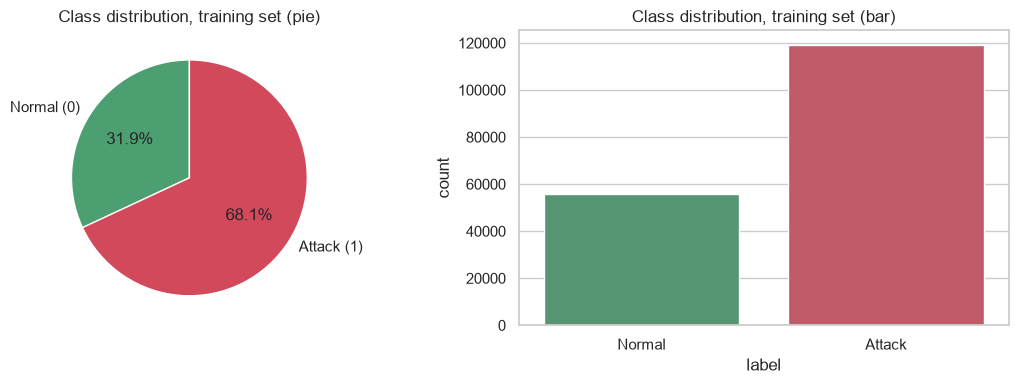

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


In [3]:
# TODO 1.3 - Class proportions and visualisation
counts = df["label"].value_counts().sort_index()
perc = (df["label"].value_counts(normalize=True).sort_index() * 100).round(2)
print(pd.DataFrame({"count": counts, "percent": perc}).rename(index={0: "Normal", 1: "Attack"}))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].pie(counts, labels=["Normal (0)", "Attack (1)"], autopct="%1.1f%%", startangle=90,
          colors=["#4C9F70", "#D1495B"])
ax[0].set_title("Class distribution, training set (pie)")
sns.countplot(x="label", hue="label", data=df, ax=ax[1],
              palette=["#4C9F70", "#D1495B"], legend=False)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["Normal", "Attack"])
ax[1].set_title("Class distribution, training set (bar)")
plt.tight_layout(); plt.show()

# attack_cat: DESCRIPTIVE exploration only (never a predictor)
if "attack_cat" in df.columns:
    print(df["attack_cat"].value_counts())

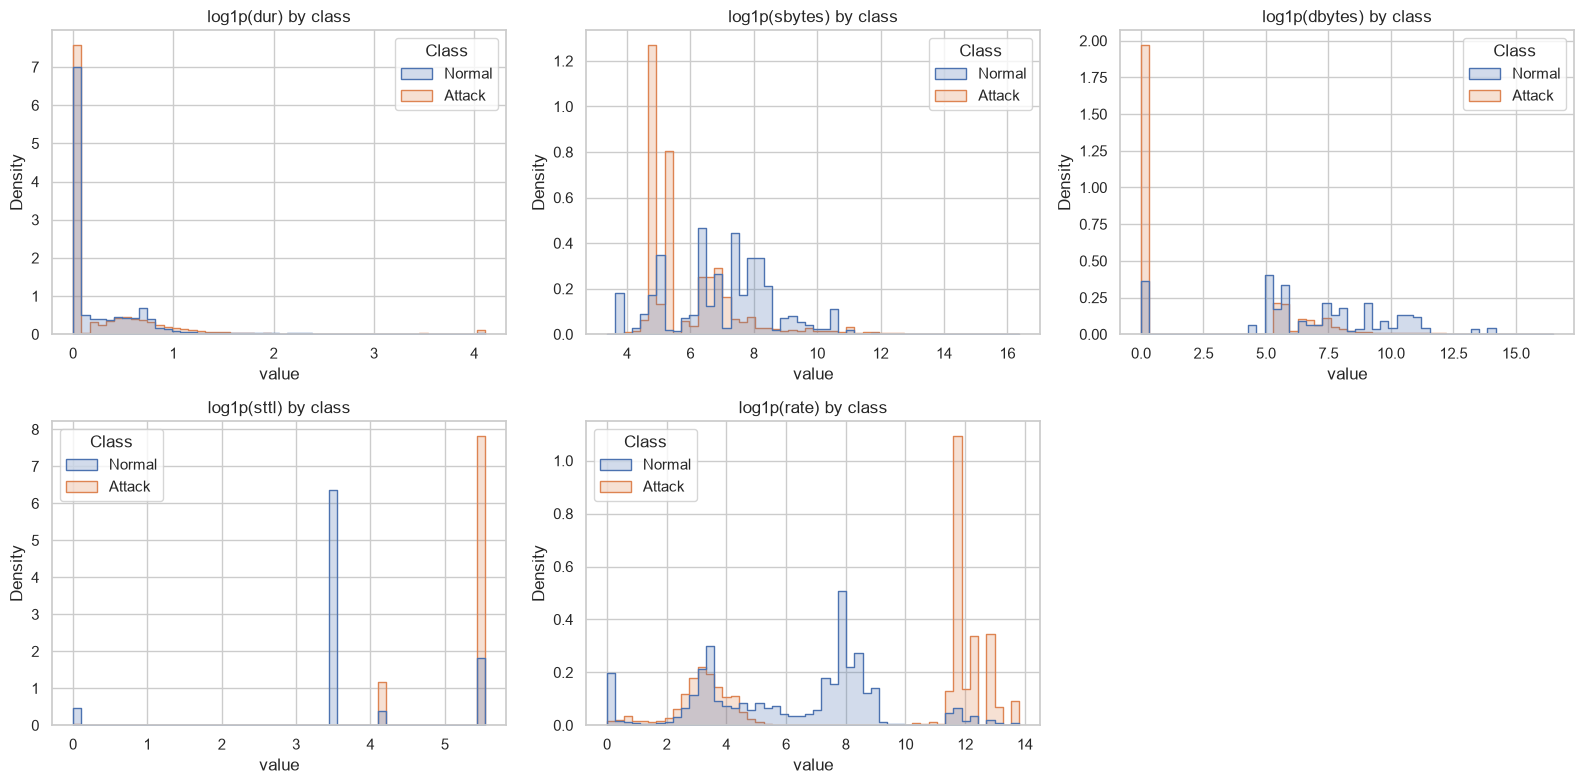

In [4]:
# TODO 1.4 - Distributions by class (log1p used for display only)
cands = ["dur", "sbytes", "dbytes", "sttl", "rate"]
feats = [c for c in cands if c in df.columns]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()
for ax, f in zip(axes, feats):
    plot_df = pd.DataFrame({
        "value": np.log1p(df[f].clip(lower=0)),
        "Class": df["label"].map({0: "Normal", 1: "Attack"}),
    })
    sns.histplot(data=plot_df, x="value", hue="Class", bins=50, stat="density",
                 common_norm=False, element="step", ax=ax)
    ax.set_title(f"log1p({f}) by class")
for ax in axes[len(feats):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

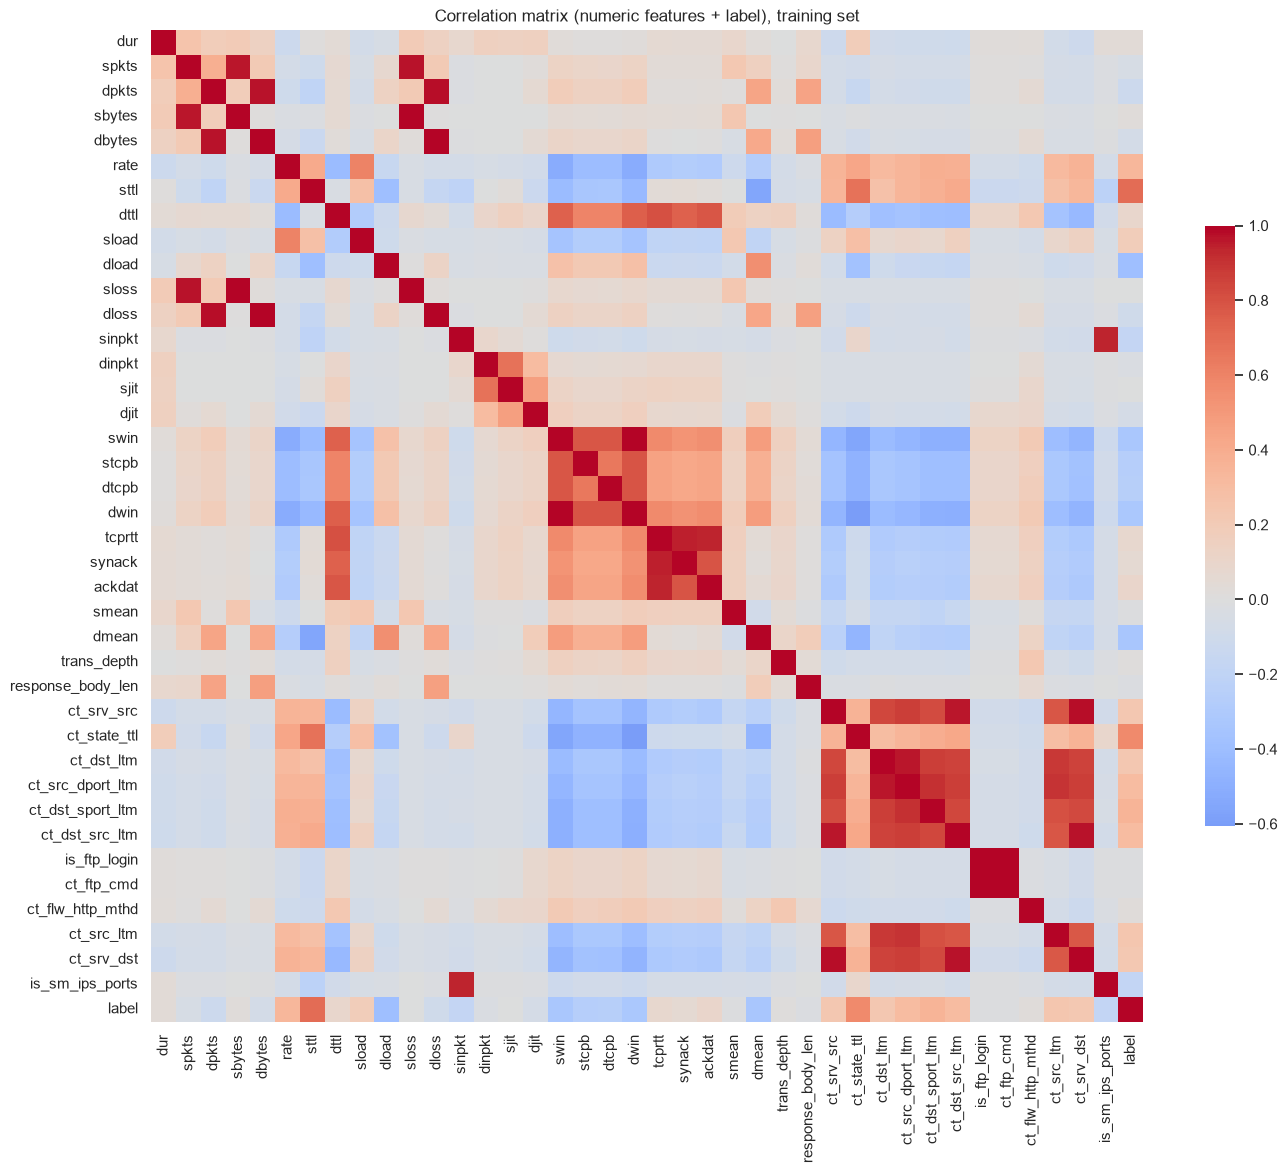

Top correlations with label:
sttl                0.692741
ct_state_ttl        0.577704
dload              -0.393739
ct_dst_sport_ltm    0.357213
dmean              -0.341806
rate                0.337979
swin               -0.333633
dwin               -0.319626
ct_src_dport_ltm    0.305579
ct_dst_src_ltm      0.303855
Name: label, dtype: float64

Most correlated feature pairs:
 is_ftp_login    ct_ftp_cmd        1.000000
dbytes          dloss             0.996504
sbytes          sloss             0.996109
swin            dwin              0.990140
ct_srv_src      ct_srv_dst        0.980323
dpkts           dloss             0.978636
ct_dst_src_ltm  ct_srv_dst        0.972370
dpkts           dbytes            0.971907
spkts           sloss             0.971069
ct_srv_src      ct_dst_src_ltm    0.967138
dtype: float64


In [5]:
# TODO 1.5 - Correlation matrix
drop_ids = [c for c in ["id", "label"] if c in df.columns]
num_cols_all = df.select_dtypes(include=np.number).columns.drop(drop_ids, errors="ignore").tolist()

corr = df[num_cols_all + ["label"]].corr()
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .6})
plt.title("Correlation matrix (numeric features + label), training set")
plt.show()

print("Top correlations with label:")
print(corr["label"].drop("label").sort_values(key=np.abs, ascending=False).head(10))

c = corr.drop(index="label", columns="label").abs()
pairs = c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack().sort_values(ascending=False)
print("\nMost correlated feature pairs:\n", pairs.head(10))

In [6]:
# TODO 1.6 - Skewness and kurtosis
skew = df[num_cols_all].skew()
kurt = df[num_cols_all].kurt()   # excess kurtosis
sk_df = pd.DataFrame({"skewness": skew, "kurtosis": kurt}).sort_values("skewness", key=np.abs, ascending=False)
display(sk_df.head(15))
print("Top-5 most skewed features:\n", sk_df.head(5))

,skewness,kurtosis
trans_depth,167.335829,34407.853786
response_body_len,76.340075,7750.978239
sbytes,45.303443,2314.880239
sloss,44.753662,2277.960322
dloss,41.380270,2942.867138
spkts,40.217703,1964.352894
dbytes,39.760864,2735.831070
dpkts,36.764114,2465.519335
dinpkt,29.679512,1158.268746
djit,29.543830,1336.151117


Top-5 most skewed features:
                      skewness      kurtosis
trans_depth        167.335829  34407.853786
response_body_len   76.340075   7750.978239
sbytes              45.303443   2314.880239
sloss               44.753662   2277.960322
dloss               41.380270   2942.867138


**Task 1 observations:**

- **Class imbalance.** The training file has 119,341 attacks (68.06%) and 56,000 normal flows (31.94%): a moderate imbalance towards the attack class. The official test file is distributed differently (45,332 attacks = 55.06%, 37,000 normal = 44.94%), and both differ from the ≈63.9% / 36.1% quoted in the assignment for the combined version. F1 and ROC-AUC are therefore more informative than accuracy alone.
- **Skewness.** The most skewed numeric features are `trans_depth` (167.3), `response_body_len` (76.3), `sbytes` (45.3), `sloss` (44.8) and `dloss` (41.4), with very large kurtosis (up to ≈34,000). These heavy right tails motivate the fold-local `log1p` step.
- **Differences between classes** (from the correlation with `label`): `sttl` (+0.69) and `ct_state_ttl` (+0.58) are higher for attacks, while `dload` (−0.39), `dmean` (−0.34), `swin` (−0.33) and `dwin` (−0.32) are lower. The class-conditional histograms (log1p scale) show the same kind of separation on `sttl` and `rate`; check them against your plots when you re-run.
- **Redundancy / similarities.** Several features are almost duplicates: `is_ftp_login` and `ct_ftp_cmd` have correlation 1.0, `dbytes`–`dloss` 0.9965, `sbytes`–`sloss` 0.9961, `swin`–`dwin` 0.990. This suggests collinearity, which matters for the linear SVM and for distance-based KNN (correlated features are counted twice).
- **Data quality.** 175,341 × 45 columns; 30 int, 11 float and 4 string columns (`proto`, `service`, `state`, `attack_cat`). 0 missing values and 0 duplicate rows. `id` is an identifier and `attack_cat` is target-derived, so both are excluded from the predictors; `attack_cat` is used only for description.

## Task 2 — Leakage-Free Preprocessing Pipeline (15 points)

### Required protocol

1. Remove non-predictive identifiers and target-derived columns from the predictors.
2. Keep the **official** train/test split (no random re-split): the test file is used only for the final evaluation, and nothing data-dependent is ever fitted on it.
3. Engineer features from the original named DataFrame columns.
4. One-hot encode nominal categorical predictors using `OneHotEncoder(handle_unknown="ignore")`.
5. Select non-negative, highly skewed numeric columns within each training fold and apply `log1p`.
6. Scale numerical features within the pipeline.

The feature engineering transformer must run **before** the `ColumnTransformer`, while the original column names are still available. All learned preprocessing must be refitted inside each cross-validation fold.

In [7]:
# TODO 2.1 - Predictors and target (official train/test files)
TARGET = "label"
drop_cols = [c for c in ["id", "attack_cat", "label", "timestamp", "stime", "ltime"]
             if c in df_train.columns]

X_train = df_train.drop(columns=drop_cols)
y_train = df_train[TARGET].astype(int)
X_test  = df_test.drop(columns=drop_cols)
y_test  = df_test[TARGET].astype(int)

print("Dropped:", drop_cols)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Categorical:", X_train.select_dtypes(exclude=np.number).columns.tolist())

Dropped: ['id', 'attack_cat', 'label']
X_train: (175341, 42) | X_test: (82332, 42)
Categorical: ['proto', 'service', 'state']


In [8]:
# TODO 2.2 - The OFFICIAL train/test split is retained (no random re-split)
print("Train class %:", y_train.value_counts(normalize=True).round(4).to_dict())
print("Test  class %:", y_test.value_counts(normalize=True).round(4).to_dict())

# Categories present only in the test file (handled by handle_unknown="ignore")
for col in X_train.select_dtypes(exclude=np.number).columns:
    unseen = set(X_test[col].unique()) - set(X_train[col].unique())
    print(f"Unseen {col} values in test:", unseen if unseen else "none")

# One CV splitter reused by EVERY grid search (identical folds)
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

Train class %: {1: 0.6806, 0: 0.3194}
Test  class %: {1: 0.5506, 0: 0.4494}
Unseen proto values in test: none
Unseen service values in test: none
Unseen state values in test: {'CLO', 'ACC'}


In [9]:
# TODO 2.3 - Custom feature engineering transformer
class NetworkFeatureEngineer(BaseEstimator, TransformerMixin):
    """Adds engineered features while keeping DataFrame column names."""

    def fit(self, X, y=None):
        self.feature_names_in_ = list(X.columns)
        return self

    def transform(self, X):
        X = X.copy()
        has = lambda *cols: all(c in X.columns for c in cols)

        if has("dbytes"):
            # log1p only valid for non-negative values
            X["log_dbytes"] = np.log1p(X["dbytes"].where(X["dbytes"] >= 0))
        if has("smean", "dmean"):
            X["mean_diff"] = X["smean"] - X["dmean"]
        if has("sbytes", "spkts"):
            X["bytes_per_source_packet"] = X["sbytes"] / (X["spkts"] + 1)
        if has("dbytes", "dpkts"):
            X["bytes_per_destination_packet"] = X["dbytes"] / (X["dpkts"] + 1)
        # Extra feature: packet asymmetry. Scans/DoS often send many packets with few or no replies.
        if has("spkts", "dpkts"):
            X["src_dst_pkt_ratio"] = X["spkts"] / (X["dpkts"] + 1)

        new_cols = ["log_dbytes", "mean_diff", "bytes_per_source_packet",
                    "bytes_per_destination_packet", "src_dst_pkt_ratio"]
        for c in new_cols:
            if c in X.columns:
                X[c] = X[c].replace([np.inf, -np.inf], np.nan)   # imputer handles NaN later
        return X

In [10]:
# TODO 2.4 - Preprocessing pipeline
class SkewedLog1p(BaseEstimator, TransformerMixin):
    """Fold-local selection: learns on the training data which columns are
    non-negative, non-binary and highly skewed, then applies log1p to them."""

    def __init__(self, skew_threshold=2.0, min_unique=3):
        self.skew_threshold = skew_threshold
        self.min_unique = min_unique

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        nonneg = np.nanmin(X, axis=0) >= 0
        skew = np.nan_to_num(stats.skew(X, axis=0, nan_policy="omit"))
        nunique = np.array([np.unique(X[:, j]).size for j in range(X.shape[1])])
        self.skew_ = skew
        self.log_mask_ = nonneg & (skew > self.skew_threshold) & (nunique >= self.min_unique)
        return self

    def transform(self, X):
        X = np.array(X, dtype=float, copy=True)
        m = self.log_mask_
        X[:, m] = np.log1p(np.clip(X[:, m], 0, None))   # clip guards unseen negative values
        return X


numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("log", SkewedLog1p(skew_threshold=2.0)),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore")),
])

column_transformer = ColumnTransformer([
    ("num", numeric_pipe, make_column_selector(dtype_include=np.number)),
    ("cat", categorical_pipe, make_column_selector(dtype_exclude=np.number)),
])

# Feature engineering runs BEFORE the ColumnTransformer (column names still exist)
preprocessing = Pipeline([
    ("fe", NetworkFeatureEngineer()),
    ("columns", column_transformer),
])

In [11]:
# TODO 2.5 - Fit on X_train only and verify leakage-free behaviour
prep_check = clone(preprocessing)
Xt_train = prep_check.fit_transform(X_train)          # fitted on TRAIN only
print("Transformed train shape:", Xt_train.shape)

data = Xt_train.data if hasattr(Xt_train, "indptr") else np.asarray(Xt_train)
print("All finite:", np.isfinite(data).all())

num_fit = prep_check.named_steps["columns"].named_transformers_["num"]
print("Log1p applied to", num_fit.named_steps["log"].log_mask_.sum(), "numeric columns")

# Leakage check: scaler statistics differ from fold to fold
print("\nScaler mean of the first numeric column, per CV fold:")
for i, (tr, _) in enumerate(skf.split(X_train, y_train)):
    p = clone(preprocessing).fit(X_train.iloc[tr])
    sc = p.named_steps["columns"].named_transformers_["num"].named_steps["scale"]
    print(f"  fold {i+1}: {sc.mean_[0]:.6f}")

Transformed train shape: (175341, 199)
All finite: True
Log1p applied to 29 numeric columns

Scaler mean of the first numeric column, per CV fold:
  fold 1: 0.338884
  fold 2: 0.337058
  fold 3: 0.339075
  fold 4: 0.338189
  fold 5: 0.339605


**Task 2 justification:**

- **Split before fitting.** Any statistic learned from the test data (scaler mean/variance, skewness used to choose log columns, category vocabulary) would leak information about the evaluation set and make the test score optimistic. Here the official train/test files are kept separate, and all preprocessing is fitted on training data only; inside cross-validation it is refitted on each training fold (see the fold-specific scaler means: 0.3371 to 0.3396 across the five folds).
- **Feature engineering.** The transformer runs first, while the original column names still exist. `log_dbytes` compresses a heavy tail; `mean_diff = smean − dmean` captures asymmetry between request and response packet size; `bytes_per_source_packet` and `bytes_per_destination_packet` describe packet size (bulk transfer vs small probes); `src_dst_pkt_ratio = spkts / (dpkts + 1)` is the extra feature: scans and flood-type attacks tend to send many packets with few or no replies. All denominators use `+1`, and infinite values are replaced by NaN and imputed.
- **One-hot encoding** (`proto`, `service`, `state`) because these are nominal: integer codes would impose a false order. `handle_unknown="ignore"` is needed because the test file contains states (`CLO`, `ACC`) never seen in training.
- **Imputation** (median / most frequent) is a safeguard for NaN created by the engineered ratios; the raw data has no missing values.
- **Selective `log1p`.** Columns that are non-negative, non-binary and with skewness above 2 *in the training fold* are log-transformed (29 columns on the full training set). The decision is learned per fold, never from the test set.
- **Scaling.** `StandardScaler` is applied to the numeric block before it is concatenated with the one-hot block, so sparse data is never centred. It is essential for KNN and SVM (distance/margin based) and helps MLP optimisation.
- **Port numbers.** The official files used here contain no port columns, so no adaptation was needed. In general ports are identifiers, not quantities, so dividing byte counts by a port number would have no meaning.

## Shared evaluation utilities

The next cell defines common helpers used by the model tasks. For each model:

- Class metrics use predicted labels.
- ROC-AUC uses a continuous decision score or positive-class probability.
- Log-loss, MAE and RMSE use positive-class probabilities.
- If a model does not provide probabilities, probability calibration is required before probability metrics can be reported.

In [12]:
# TODO 2.6 - Evaluation helpers
def positive_class_probabilities(estimator, X):
    if not hasattr(estimator, "predict_proba"):
        raise AttributeError("Estimator has no predict_proba (calibrate it first).")
    proba = estimator.predict_proba(X)
    return proba[:, list(estimator.classes_).index(1)]

def positive_class_scores(estimator, X):
    if hasattr(estimator, "predict_proba"):
        return positive_class_probabilities(estimator, X)
    return estimator.decision_function(X)

def metrics_from_outputs(name, y_true, y_pred, scores, proba=None):
    out = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "AUC-ROC": roc_auc_score(y_true, scores),
    }
    if proba is not None:
        out["Log-Loss"] = log_loss(y_true, np.clip(proba, 1e-15, 1 - 1e-15))
        out["MAE_prob"] = mean_absolute_error(y_true, proba)            # labels vs P(attack)
        out["RMSE_prob"] = float(np.sqrt(mean_squared_error(y_true, proba)))
    else:
        out["Log-Loss"] = np.nan    # not computable without calibration
        out["MAE_prob"] = np.nan
        out["RMSE_prob"] = np.nan
    return out

def evaluate_classifier(estimator, X_eval, y_eval, name):
    t0 = time.perf_counter()
    y_pred = estimator.predict(X_eval)
    infer_time = time.perf_counter() - t0
    scores = positive_class_scores(estimator, X_eval)
    proba = positive_class_probabilities(estimator, X_eval) if hasattr(estimator, "predict_proba") else None
    res = metrics_from_outputs(name, y_eval, y_pred, scores, proba)
    res["Inference time (s)"] = infer_time
    return res

test_results = {}

## Task 3 — K-Nearest Neighbors (KNN) (15 points)

Use the common preprocessing pipeline. Tune the required grid with stratified five-fold CV on the training set only.

In [13]:
# TODO 3.1 - 3.3 - Fast KNN tuning (equivalent to GridSearchCV on the required grid).
# For each fold and metric, the 25 nearest neighbours are computed ONCE; the votes for every
# (k, weights) combination are then derived from that single result.
# Preprocessing is refitted on each fold's training part only (leakage-free).
K_LIST  = [3, 5, 7, 11, 15, 21, 25]
WEIGHTS = ["uniform", "distance"]
METRICS = ["euclidean", "manhattan"]
K_MAX   = max(K_LIST)

def to_dense32(M):
    """Dense float32 is much faster for brute-force distances than sparse."""
    return (M.toarray() if hasattr(M, "toarray") else np.asarray(M)).astype(np.float32)

def knn_vote(labels, dist, k, weights):
    """Predicted classes for given k/weights from the precomputed K_MAX neighbours."""
    lab = labels[:, :k]
    if weights == "uniform":
        p = lab.mean(axis=1)
    else:
        d = dist[:, :k].astype(np.float64)
        with np.errstate(divide="ignore"):
            w = 1.0 / d
        zero = (d == 0).any(axis=1)              # exact matches dominate (same rule as sklearn)
        if zero.any():
            w[zero] = (d[zero] == 0).astype(float)
        p = (w * lab).sum(axis=1) / w.sum(axis=1)
    return (p > 0.5).astype(int)

y_arr = np.asarray(y_train)
combos = [(k, w, m) for m in METRICS for w in WEIGHTS for k in K_LIST]
fold_scores = {c: [] for c in combos}

t0 = time.perf_counter()
for f, (tr, va) in enumerate(skf.split(X_train, y_train), start=1):
    prep = clone(preprocessing).fit(X_train.iloc[tr])
    Xtr = to_dense32(prep.transform(X_train.iloc[tr]))
    Xva = to_dense32(prep.transform(X_train.iloc[va]))
    ytr, yva = y_arr[tr], y_arr[va]

    for m in METRICS:
        nn = NearestNeighbors(n_neighbors=K_MAX, metric=m, algorithm="brute", n_jobs=-1).fit(Xtr)
        dist, idx = nn.kneighbors(Xva)           # ONE search serves all k and both weightings
        labels = ytr[idx]
        for w in WEIGHTS:
            for k in K_LIST:
                fold_scores[(k, w, m)].append(f1_score(yva, knn_vote(labels, dist, k, w)))
    print(f"fold {f}/{N_SPLITS} done ({time.perf_counter()-t0:.0f}s)")

# GridSearchCV-like results object (same attribute names used by later cells)
mean_s = np.array([np.mean(fold_scores[c]) for c in combos])
std_s  = np.array([np.std(fold_scores[c])  for c in combos])
cv_results = {
    "param_clf__n_neighbors": np.array([c[0] for c in combos]),
    "param_clf__weights":     np.array([c[1] for c in combos]),
    "param_clf__metric":      np.array([c[2] for c in combos]),
    "mean_test_score": mean_s,
    "std_test_score":  std_s,
}
for i in range(N_SPLITS):
    cv_results[f"split{i}_test_score"] = np.array([fold_scores[c][i] for c in combos])

best_i = int(np.argmax(mean_s))
best_k, best_w, best_m = combos[best_i]
best_params = {"clf__n_neighbors": best_k, "clf__weights": best_w, "clf__metric": best_m}

t1 = time.perf_counter()
best_pipe = Pipeline([
    ("prep", clone(preprocessing)),
    ("clf", KNeighborsClassifier(n_neighbors=best_k, weights=best_w, metric=best_m, n_jobs=-1)),
]).fit(X_train, y_train)
refit_time = time.perf_counter() - t1

grid_knn = SimpleNamespace(
    best_params_=best_params, best_score_=mean_s[best_i], best_index_=best_i,
    cv_results_=cv_results, best_estimator_=best_pipe, refit_time_=refit_time,
)

print(f"\nKNN tuning time: {time.perf_counter()-t0:.0f}s")
print("Best params:", grid_knn.best_params_)
print(f"Best CV F1: {grid_knn.best_score_:.4f}")

fold 1/5 done (146s)
fold 2/5 done (293s)
fold 3/5 done (441s)
fold 4/5 done (594s)
fold 5/5 done (745s)

KNN tuning time: 747s
Best params: {'clf__n_neighbors': 25, 'clf__weights': 'distance', 'clf__metric': 'manhattan'}
Best CV F1: 0.9668


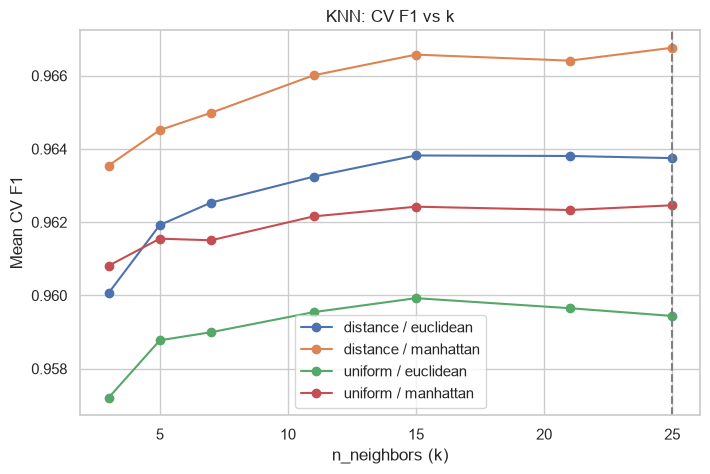

In [14]:
# TODO 3.4 - CV F1 vs k
res = pd.DataFrame(grid_knn.cv_results_)
res["k"] = res["param_clf__n_neighbors"].astype(int)

plt.figure(figsize=(8, 5))
for (w, m), g in res.groupby(["param_clf__weights", "param_clf__metric"]):
    g = g.sort_values("k")
    plt.plot(g["k"], g["mean_test_score"], marker="o", label=f"{w} / {m}")
plt.axvline(grid_knn.best_params_["clf__n_neighbors"], ls="--", c="gray")
plt.xlabel("n_neighbors (k)"); plt.ylabel("Mean CV F1")
plt.title("KNN: CV F1 vs k"); plt.legend(); plt.show()

In [15]:
# TODO 3.5 - Final KNN: refit on the full training set, evaluate ONCE on the test set
class FastKNN(ClassifierMixin, BaseEstimator):
    """KNN with preprocessing; dense float32 + brute force + cached predict_proba."""
    def __init__(self, preprocessing=None, n_neighbors=5, weights="uniform", metric="euclidean"):
        self.preprocessing = preprocessing
        self.n_neighbors = n_neighbors
        self.weights = weights
        self.metric = metric

    @staticmethod
    def _dense(M):
        return (M.toarray() if hasattr(M, "toarray") else np.asarray(M)).astype(np.float32)

    def fit(self, X, y):
        self.prep_ = clone(self.preprocessing).fit(X)          # fitted on training data only
        self.knn_ = KNeighborsClassifier(
            n_neighbors=self.n_neighbors, weights=self.weights, metric=self.metric,
            algorithm="brute", n_jobs=-1
        ).fit(self._dense(self.prep_.transform(X)), y)
        self.classes_ = self.knn_.classes_
        self._cx = None
        return self

    def predict_proba(self, X):
        if getattr(self, "_cx", None) is X:                     # same object already scored
            return self._cp
        p = self.knn_.predict_proba(self._dense(self.prep_.transform(X)))
        self._cx, self._cp = X, p
        return p

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


bp = grid_knn.best_params_
t0 = time.perf_counter()
best_knn = FastKNN(
    preprocessing=preprocessing,
    n_neighbors=bp["clf__n_neighbors"],
    weights=bp["clf__weights"],
    metric=bp["clf__metric"],
).fit(X_train, y_train)
knn_refit_time = time.perf_counter() - t0

t0 = time.perf_counter()
test_results["KNN"] = evaluate_classifier(best_knn, X_test, y_test, "KNN")
print(f"Evaluation took {time.perf_counter()-t0:.0f}s")
test_results["KNN"]["Train time (s)"] = knn_refit_time
display(pd.DataFrame([test_results["KNN"]]).round(4))

Evaluation took 417s


,Model,Accuracy,Precision,Recall,F1,AUC-ROC,Log-Loss,MAE_prob,RMSE_prob,Inference time (s),Train time (s)
0,KNN,0.8588,0.8099,0.9715,0.8834,0.9693,0.4654,0.1404,0.2974,417.0827,2.7955


### NEW — Sanity check: the fast KNN tuning matches `KNeighborsClassifier`

This compares the fold-1 F1 of the best configuration computed by the neighbour-reuse loop (cell 22) with the standard scikit-learn `KNeighborsClassifier` on the same fold. The two numbers should be identical or differ only by tie-breaking.

In [16]:
# NEW - validate the custom KNN tuning against sklearn's KNeighborsClassifier (fold 1, best config)
tr, va = next(iter(skf.split(X_train, y_train)))
prep_chk = clone(preprocessing).fit(X_train.iloc[tr])
Xtr_chk = to_dense32(prep_chk.transform(X_train.iloc[tr]))
Xva_chk = to_dense32(prep_chk.transform(X_train.iloc[va]))
ref_knn = KNeighborsClassifier(n_neighbors=best_k, weights=best_w, metric=best_m,
                               algorithm="brute", n_jobs=-1).fit(Xtr_chk, y_arr[tr])
f1_sklearn = f1_score(y_arr[va], ref_knn.predict(Xva_chk))
f1_custom = fold_scores[(best_k, best_w, best_m)][0]
print(f"Fold-1 F1 | sklearn KNeighborsClassifier: {f1_sklearn:.4f} | custom neighbour-reuse: {f1_custom:.4f}")
print("Difference:", abs(f1_sklearn - f1_custom))

Fold-1 F1 | sklearn KNeighborsClassifier: 0.9661 | custom neighbour-reuse: 0.9661
Difference: 0.0


**Result of the check:** *[write after running: the two F1 values and the conclusion]*

**KNN discussion:**

- **Effect of k.** The best configuration is k = 25 with distance weighting and Manhattan distance (CV F1 = 0.9668). Because 25 is the *largest* value in the required grid, F1 was still improving (or flat) at the edge of the grid, so the optimum may lie beyond it; read the F1-vs-k plot to see whether the curve flattens. Small k follows local noise (low bias, high variance); larger k smooths the boundary.
- **Standardization.** KNN decides by distances. Without scaling, features with large ranges (e.g. `sload`, `stcpb`, byte counts) dominate the distance and the small-range features are effectively ignored. Standardization (after `log1p` on the heavy-tailed columns) puts the features on comparable scales so that each contributes to the geometry. One-hot features are also in a comparable 0/1 range.
- **Cost.** KNN trains almost instantly (2.8 s) but is slow at prediction: about 367 s to score the 82,332 test rows, because every query is compared with all 175,341 training points.

## Task 4 — Support Vector Machines (SVM) (15 points)

Implement both a linear SVM and an RBF-kernel SVM. `LinearSVC` exposes `decision_function()` but does not provide `predict_proba()` by default. The RBF SVC must be trained on a stratified subsample of at most 20,000 records drawn only from `X_train` and `y_train`.

In [17]:
# TODO 4.1 - Linear SVM (LinearSVC has no predict_proba)
lin_pipe = Pipeline([
    ("prep", clone(preprocessing)),
    ("clf", LinearSVC(dual=False, max_iter=5000, random_state=RANDOM_STATE)),
])
grid_lin = GridSearchCV(lin_pipe, {"clf__C": [0.01, 0.1, 1, 10]},
                        scoring="f1", cv=skf, refit=True, n_jobs=-1, verbose=1)
grid_lin.fit(X_train, y_train)
print("Linear SVM best params:", grid_lin.best_params_)
print(f"Linear SVM best CV F1: {grid_lin.best_score_:.4f}")

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Linear SVM best params: {'clf__C': 10}
Linear SVM best CV F1: 0.9547


In [18]:
# TODO 4.2 - Stratified RBF-SVM subsample (training data only, max 20,000 rows)
SVM_MAX = 20_000
if len(X_train) > SVM_MAX:
    X_svm, _, y_svm, _ = train_test_split(
        X_train, y_train, train_size=SVM_MAX, stratify=y_train, random_state=RANDOM_STATE
    )
else:
    X_svm, y_svm = X_train.copy(), y_train.copy()

print("RBF subset size:", len(X_svm))
print("Subset class %:", y_svm.value_counts(normalize=True).round(4).to_dict())
print("Full-train class %:", y_train.value_counts(normalize=True).round(4).to_dict())

RBF subset size: 20000
Subset class %: {1: 0.6806, 0: 0.3194}
Full-train class %: {1: 0.6806, 0: 0.3194}


In [19]:
# TODO 4.3 - RBF SVM tuning on the training-only subset
rbf_pipe = Pipeline([
    ("prep", clone(preprocessing)),
    ("clf", SVC(kernel="rbf", cache_size=1000, random_state=RANDOM_STATE)),
])
rbf_grid = {"clf__C": [0.01, 0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1, 1]}
grid_rbf = GridSearchCV(rbf_pipe, rbf_grid, scoring="f1", cv=skf,
                        refit=True, n_jobs=-1, verbose=1)
grid_rbf.fit(X_svm, y_svm)       # training-only subset
print("RBF SVM best params:", grid_rbf.best_params_)
print(f"RBF SVM best CV F1 (on subset): {grid_rbf.best_score_:.4f}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits


RBF SVM best params: {'clf__C': 10, 'clf__gamma': 'scale'}
RBF SVM best CV F1 (on subset): 0.9586


In [20]:
# TODO 4.4 - Support vectors
svc = grid_rbf.best_estimator_.named_steps["clf"]
print("Support vectors per class (Normal, Attack):", svc.n_support_)
print("Total support vectors:", svc.n_support_.sum(), "out of", len(X_svm),
      f"({svc.n_support_.sum()/len(X_svm):.1%} of the subset)")

Support vectors per class (Normal, Attack): [1313 1446]
Total support vectors: 2759 out of 20000 (13.8% of the subset)


In [21]:
# TODO 4.5 - Linear vs RBF on the untouched test set
test_results["Linear SVM"] = evaluate_classifier(grid_lin.best_estimator_, X_test, y_test, "Linear SVM")
test_results["Linear SVM"]["Train time (s)"] = grid_lin.refit_time_
test_results["RBF SVM"] = evaluate_classifier(grid_rbf.best_estimator_, X_test, y_test, "RBF SVM")
test_results["RBF SVM"]["Train time (s)"] = grid_rbf.refit_time_

svm_cmp = pd.DataFrame([test_results["Linear SVM"], test_results["RBF SVM"]]).set_index("Model")
svm_cmp["Best CV F1"] = [grid_lin.best_score_, grid_rbf.best_score_]
display(svm_cmp.round(4))

,Accuracy,Precision,Recall,F1,AUC-ROC,Log-Loss,MAE_prob,RMSE_prob,Inference time (s),Train time (s),Best CV F1
Model,,,,,,,,,,,
Linear SVM,0.8143,0.7545,0.9824,0.8535,0.9573,NaN,NaN,NaN,0.5541,22.8050,0.9547
RBF SVM,0.8302,0.7680,0.9909,0.8654,0.9616,NaN,NaN,NaN,17.5784,8.4214,0.9586


**SVM discussion:**

| | Linear SVM (full train) | RBF SVM (20k subset) |
|---|---|---|
| Best params | C = 10 | C = 10, gamma = scale |
| Best CV F1 | 0.9547 | 0.9586 |
| Test F1 / AUC | 0.8535 / 0.9573 | 0.8654 / 0.9616 |

- **Support vectors.** The RBF model keeps 2,759 support vectors out of 20,000 (13.8%; 1,313 Normal and 1,446 Attack). A moderate fraction means that most points are far from the boundary and only the ones near or inside the margin define it: the classes are reasonably separable, but the boundary is not trivial.
- **RBF vs linear.** RBF is slightly better on CV, on test F1 and on AUC, even though it saw only about 11% of the training data. The gain is modest (≈ +0.01 F1), which suggests the problem is largely, but not perfectly, linearly separable after preprocessing. Note that the best C (10) lies at the edge of the grid, so larger values were not explored.
- **Limitations.** The two CV scores are not strictly comparable (the RBF score is computed on a 20k subset, the linear score on the full training set), and the RBF model cannot use the remaining 155k records. The nonlinear kernel was not assumed to win: it was selected on training-CV F1 only.
- **Probability metrics.** Log-loss/MAE/RMSE need calibrated probabilities (see the calibrated row in the final table). *[Add one sentence here about the calibrated-SVM diagnostic cell after you run it.]*

## Task 5 — Multilayer Perceptron (MLP) (15 points)

Tune the required architecture, activation, regularization and learning-rate settings. Enable early stopping. The `loss_curve_` attribute records **training loss**, not validation loss.

In [22]:
# TODO 5.1 - MLP tuning
mlp_pipe = Pipeline([
    ("prep", clone(preprocessing)),
    ("clf", MLPClassifier(early_stopping=True, validation_fraction=0.1,
                          max_iter=200, random_state=RANDOM_STATE)),
])
mlp_grid = {
    "clf__hidden_layer_sizes": [(64,), (128, 64), (128, 64, 32)],
    "clf__activation": ["relu", "tanh"],
    "clf__alpha": [1e-4, 1e-3],
    "clf__learning_rate_init": [1e-3, 1e-2],
}
grid_mlp = GridSearchCV(mlp_pipe, mlp_grid, scoring="f1", cv=skf,
                        refit=True, n_jobs=-1, verbose=1)
grid_mlp.fit(X_train, y_train)
print("MLP best params:", grid_mlp.best_params_)
print(f"MLP best CV F1: {grid_mlp.best_score_:.4f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
MLP best params: {'clf__activation': 'tanh', 'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (128, 64, 32), 'clf__learning_rate_init': 0.001}
MLP best CV F1: 0.9640


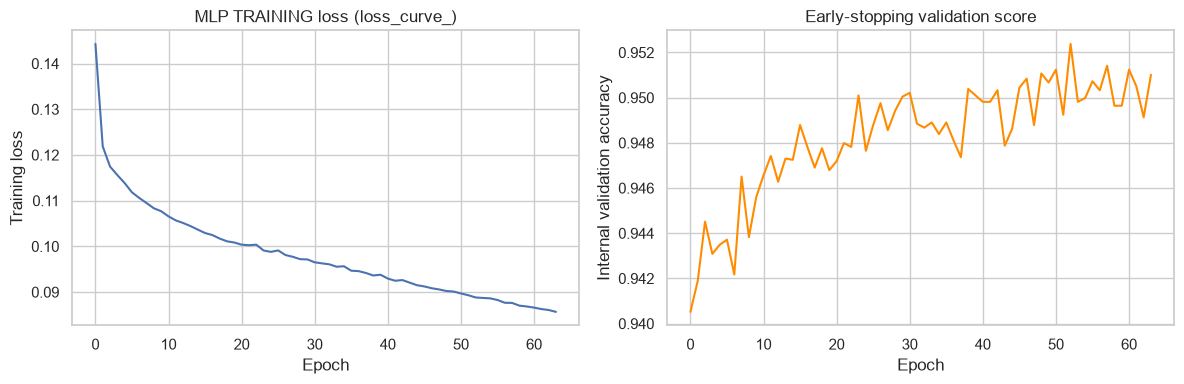

Iterations run (n_iter_): 64 | max_iter: 200
Stopped early: True
best_validation_score_: 0.9524


In [23]:
# TODO 5.2 - Training loss curve
mlp = grid_mlp.best_estimator_.named_steps["clf"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(mlp.loss_curve_)
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Training loss")
ax[0].set_title("MLP TRAINING loss (loss_curve_)")
ax[1].plot(mlp.validation_scores_, c="darkorange")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Internal validation accuracy")
ax[1].set_title("Early-stopping validation score")
plt.tight_layout(); plt.show()

print("Iterations run (n_iter_):", mlp.n_iter_, "| max_iter:", mlp.max_iter)
print("Stopped early:", mlp.n_iter_ < mlp.max_iter)
print("best_validation_score_:", round(mlp.best_validation_score_, 4))

In [24]:
# TODO 5.3 - MLP on the held-out test set
best_mlp = grid_mlp.best_estimator_
test_results["MLP"] = evaluate_classifier(best_mlp, X_test, y_test, "MLP")
test_results["MLP"]["Train time (s)"] = grid_mlp.refit_time_
display(pd.DataFrame([test_results["MLP"]]).round(4))

,Model,Accuracy,Precision,Recall,F1,AUC-ROC,Log-Loss,MAE_prob,RMSE_prob,Inference time (s),Train time (s)
0,MLP,0.8637,0.8201,0.9639,0.8862,0.972,0.3016,0.1407,0.3059,0.9383,172.4406


**MLP discussion:**

- **Best configuration:** hidden layers (128, 64, 32), `tanh`, alpha = 1e-4, learning rate 1e-3, CV F1 = 0.9640. It is also the best model on the held-out test set (F1 0.8862, AUC 0.9720, lowest log-loss 0.3016).
- **Does depth always help?** No. The deepest network won here, but the CV standard deviation is about 0.001, so differences between architectures are small, and the grid does not isolate depth from the other hyperparameters. A deeper network adds capacity (lower bias) but also variance, training time and sensitivity to learning rate; it only helps when the extra capacity is supported by enough data and regularization.
- **Role of alpha.** `alpha` is the L2 weight penalty: larger values shrink the weights and smooth the decision function (more bias, less variance). With 175k samples and early stopping, the smaller value (1e-4) was enough.
- **Early stopping.** It occurred: the best model stopped after 64 iterations (`n_iter_ = 64` out of `max_iter = 200`).
- **Training vs validation loss.** `loss_curve_` stores the loss computed on the training portion (90% of the data) at each epoch. The 10% internal validation split is used only to decide when to stop, and its score is stored separately in `validation_scores_` (accuracy), which is why the second panel is plotted separately.

## Task 6 — Cross-Validation, Held-Out Evaluation and Comparison (15 points)

### Important distinction

- The GridSearchCV best score is a **model-selection score** obtained on training folds.
- The held-out test set is used once, after selecting the model configuration.
- Do not tune hyperparameters on the test set.
- Optional paired t-tests are exploratory only; five fold scores are few and not fully independent.

In [25]:
# TODO 6.1 - Best training-CV F1 scores (model-selection scores, NOT test scores)
def cv_summary(name, grid):
    i = grid.best_index_
    return {"Model": name, "Best CV F1": grid.best_score_,
            "CV F1 std": grid.cv_results_["std_test_score"][i],
            "Best params": grid.best_params_}

cv_table = pd.DataFrame([
    cv_summary("KNN", grid_knn),
    cv_summary("Linear SVM", grid_lin),
    cv_summary("RBF SVM (20k subset)", grid_rbf),
    cv_summary("MLP", grid_mlp),
])
display(cv_table)

,Model,Best CV F1,CV F1 std,Best params
0,KNN,0.966762,0.000674,"{'clf__n_neighbors': 25, 'clf__weights': 'dist..."
1,Linear SVM,0.954745,0.000532,{'clf__C': 10}
2,RBF SVM (20k subset),0.958610,0.000807,"{'clf__C': 10, 'clf__gamma': 'scale'}"
3,MLP,0.964018,0.000998,"{'clf__activation': 'tanh', 'clf__alpha': 0.00..."


In [26]:
# TODO 6.2 - Select the SVM variant using TRAINING-CV F1 only
if grid_rbf.best_score_ > grid_lin.best_score_:
    best_svm, selected_svm_name = grid_rbf.best_estimator_, "RBF SVM"
else:
    best_svm, selected_svm_name = grid_lin.best_estimator_, "Linear SVM"
print("Selected SVM variant (by training-CV F1):", selected_svm_name)
# Caveat: the RBF CV score comes from a 20k subset, the linear one from the full training set.

Selected SVM variant (by training-CV F1): RBF SVM


In [27]:
# TODO 6.3 - Held-out comparison table
class CappedFit(ClassifierMixin, BaseEstimator):
    """Fits a clone of `estimator` on a stratified subsample of at most `max_samples`
    rows of whatever training data it receives (cap applies inside every CV fold)."""
    def __init__(self, estimator, max_samples=20_000, random_state=RANDOM_STATE):
        self.estimator = estimator
        self.max_samples = max_samples
        self.random_state = random_state

    def fit(self, X, y):
        y = np.asarray(y)
        if len(y) > self.max_samples:
            idx, _ = train_test_split(np.arange(len(y)), train_size=self.max_samples,
                                      stratify=y, random_state=self.random_state)
            X, y = X.iloc[idx], y[idx]
        self.estimator_ = clone(self.estimator).fit(X, y)
        self.classes_ = self.estimator_.classes_
        return self

    def predict(self, X):
        return self.estimator_.predict(X)

    @available_if(lambda self: hasattr(self.estimator, "decision_function"))
    def decision_function(self, X):
        return self.estimator_.decision_function(X)

    @available_if(lambda self: hasattr(self.estimator, "predict_proba"))
    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)


def make_svm_base():
    return CappedFit(clone(best_svm)) if selected_svm_name == "RBF SVM" else clone(best_svm)

def make_calibrated_svm():
    return CalibratedClassifierCV(make_svm_base(), cv=3, method="sigmoid")

# Selected SVM, uncalibrated, as tuned
test_results["SVM"] = evaluate_classifier(best_svm, X_test, y_test, f"SVM ({selected_svm_name})")
test_results["SVM"]["Train time (s)"] = (grid_rbf if selected_svm_name == "RBF SVM" else grid_lin).refit_time_

# Extra row: calibrated SVM (fitted on training data only) to obtain probability metrics
svm_cal = make_calibrated_svm().fit(X_train, y_train)
test_results["SVM (calibrated)"] = evaluate_classifier(
    svm_cal, X_test, y_test, f"SVM ({selected_svm_name}) + calibration")

final_table = pd.DataFrame([test_results["KNN"], test_results["SVM"],
                            test_results["SVM (calibrated)"], test_results["MLP"]]).set_index("Model")
cols = ["Accuracy", "Precision", "Recall", "F1", "AUC-ROC", "Log-Loss", "MAE_prob", "RMSE_prob",
        "Train time (s)", "Inference time (s)"]
display(final_table[cols].round(4))
print("NaN = metric not computable without probability calibration.")
print("MAE_prob / RMSE_prob compare the binary true labels with P(Attack).")

,Accuracy,Precision,Recall,F1,AUC-ROC,Log-Loss,MAE_prob,RMSE_prob,Train time (s),Inference time (s)
Model,,,,,,,,,,
KNN,0.8588,0.8099,0.9715,0.8834,0.9693,0.4654,0.1404,0.2974,2.7955,417.0827
SVM (RBF SVM),0.8302,0.7680,0.9909,0.8654,0.9616,NaN,NaN,NaN,8.4214,15.6817
SVM (RBF SVM) + calibration,0.8301,0.7713,0.9829,0.8643,0.9176,0.3993,0.2175,0.3544,NaN,40.6528
MLP,0.8637,0.8201,0.9639,0.8862,0.9720,0.3016,0.1407,0.3059,172.4406,0.9383


NaN = metric not computable without probability calibration.
MAE_prob / RMSE_prob compare the binary true labels with P(Attack).


### NEW — Diagnostic: why is the calibrated SVM's AUC lower than the uncalibrated one?

A monotonic sigmoid calibration should not change AUC much. This cell compares the uncalibrated AUC with the AUC of each of the three base models inside `CalibratedClassifierCV`.

In [28]:
# NEW - diagnose the AUC drop after calibration
print(f"Uncalibrated {selected_svm_name} AUC (test): {roc_auc_score(y_test, best_svm.decision_function(X_test)):.4f}")
print(f"Calibrated AUC (test, mean of 3 calibrated models): {roc_auc_score(y_test, svm_cal.predict_proba(X_test)[:, 1]):.4f}")
for i, cc in enumerate(svm_cal.calibrated_classifiers_):
    base = getattr(cc, "estimator", None) or getattr(cc, "base_estimator")
    print(f"  calibration fold {i}: base-model AUC on test = {roc_auc_score(y_test, base.decision_function(X_test)):.4f}")

Uncalibrated RBF SVM AUC (test): 0.9616
Calibrated AUC (test, mean of 3 calibrated models): 0.9176
  calibration fold 0: base-model AUC on test = 0.9590
  calibration fold 1: base-model AUC on test = 0.9592
  calibration fold 2: base-model AUC on test = 0.8337


**Reading:** if the per-fold base AUCs are about as low as the calibrated AUC, the drop comes from the three base models being fitted on different 20k subsamples inside the calibration folds, not from the sigmoid itself. In that case use the optional cleaner calibration in the next cell. *[write your conclusion after running]*

In [29]:
# NEW (optional) - cleaner calibration: freeze the tuned SVM and fit the sigmoid on training rows it never saw.
# Set to True only if the diagnostic above shows that the 3-fold calibration is what lowers the AUC.
USE_CLEAN_CALIBRATION = False

if USE_CLEAN_CALIBRATION:
    assert selected_svm_name == "RBF SVM", "This variant assumes the RBF SVM (fitted on X_svm only)."
    try:
        from sklearn.frozen import FrozenEstimator
        frozen_cal = lambda est: CalibratedClassifierCV(FrozenEstimator(est), method="sigmoid")
    except ImportError:                                   # older scikit-learn
        frozen_cal = lambda est: CalibratedClassifierCV(est, cv="prefit", method="sigmoid")

    # calibration rows: training rows NOT used to fit the SVM (training data only, no test data)
    X_rest, y_rest = X_train.drop(index=X_svm.index), y_train.drop(index=X_svm.index)
    X_cal, _, y_cal, _ = train_test_split(X_rest, y_rest, train_size=20_000,
                                          stratify=y_rest, random_state=RANDOM_STATE)
    svm_cal = frozen_cal(best_svm).fit(X_cal, y_cal)
    test_results["SVM (calibrated)"] = evaluate_classifier(
        svm_cal, X_test, y_test, f"SVM ({selected_svm_name}) + calibration")

    final_table = pd.DataFrame([test_results["KNN"], test_results["SVM"],
                                test_results["SVM (calibrated)"], test_results["MLP"]]).set_index("Model")
    display(final_table[cols].round(4))
    # NOTE: if you use this, also re-run the bonus cells, whose base SVM uses make_calibrated_svm().

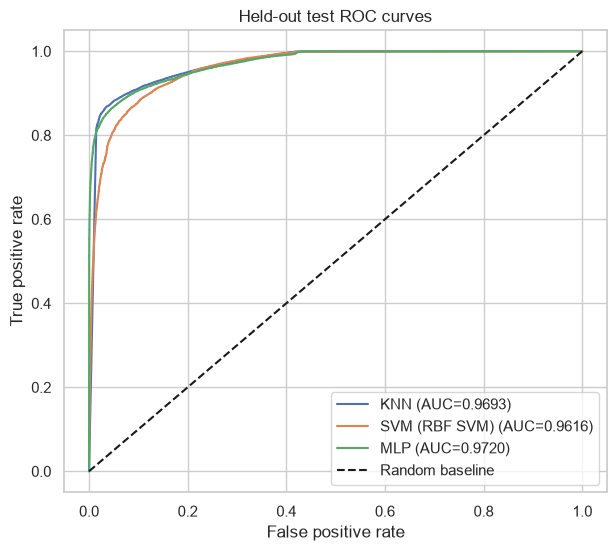

In [30]:
# TODO 6.4 - ROC curves (held-out test set)
three_models = {
    "KNN": best_knn,
    f"SVM ({selected_svm_name})": best_svm,
    "MLP": best_mlp,
}
plt.figure(figsize=(7, 6))
for name, est in three_models.items():
    s = positive_class_scores(est, X_test)
    fpr, tpr, _ = roc_curve(y_test, s)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, s):.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Random baseline")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("Held-out test ROC curves"); plt.legend(loc="lower right"); plt.show()

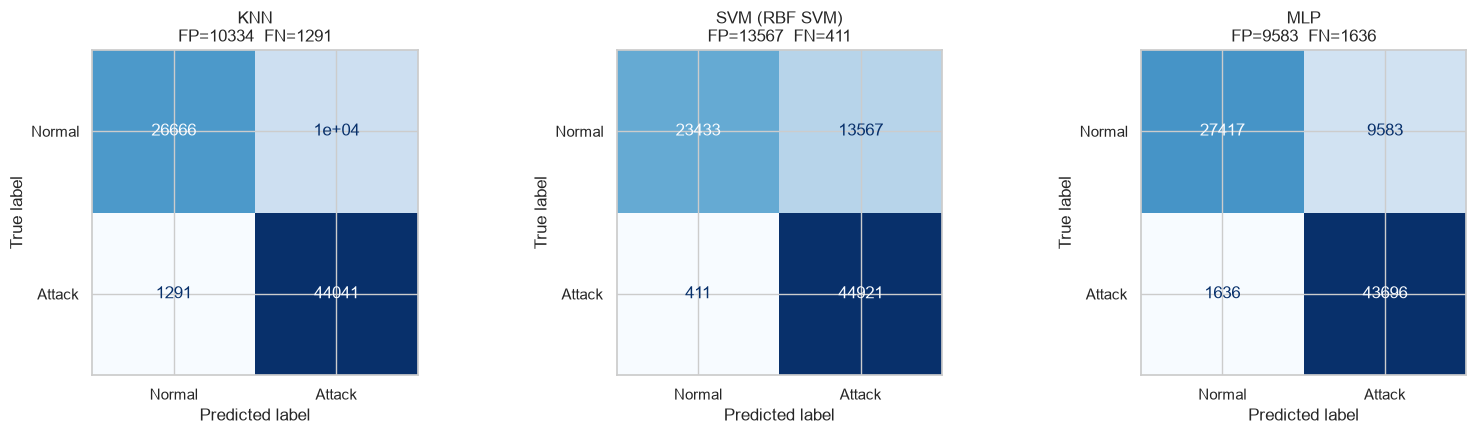

In [31]:
# TODO 6.5 - Confusion matrices (held-out test set)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, est) in zip(axes, three_models.items()):
    cm = confusion_matrix(y_test, est.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Normal", "Attack"]).plot(ax=ax, cmap="Blues", colorbar=False)
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{name}\nFP={fp}  FN={fn}")
plt.tight_layout(); plt.show()

In [32]:
# OPTIONAL TODO 6.6 - Exploratory paired t-tests on fold-wise F1
def fold_scores_from_grid(grid):
    i = grid.best_index_
    return np.array([grid.cv_results_[f"split{k}_test_score"][i] for k in range(N_SPLITS)])

# KNN, linear SVM and MLP were tuned on the same `skf` folds, so reuse their fold scores.
fold_f1 = {
    "KNN": fold_scores_from_grid(grid_knn),
    "MLP": fold_scores_from_grid(grid_mlp),
}
if selected_svm_name == "RBF SVM":
    # RBF was tuned on a subset: recompute on the same full-train folds, with the 20k cap inside each fold
    fold_f1["SVM"] = cross_val_score(CappedFit(clone(best_svm)), X_train, y_train,
                                     cv=skf, scoring="f1", n_jobs=-1)
else:
    fold_f1["SVM"] = fold_scores_from_grid(grid_lin)

print(pd.DataFrame(fold_f1).round(4))

rows = []
for a, b in combinations(fold_f1.keys(), 2):
    t, p = stats.ttest_rel(fold_f1[a], fold_f1[b])
    rows.append({"Pair": f"{a} vs {b}", "t": t, "p-value": p, "alpha": 0.05,
                 "Significant (exploratory)": p < 0.05})
display(pd.DataFrame(rows).round(4))
print("Exploratory only: 5 folds give low power, and fold scores are not independent.")

      KNN     MLP     SVM
0  0.9661  0.9640  0.9557
1  0.9675  0.9634  0.9572
2  0.9673  0.9650  0.9590
3  0.9670  0.9652  0.9580
4  0.9658  0.9625  0.9583


,Pair,t,p-value,alpha,Significant (exploratory)
0,KNN vs MLP,6.5078,0.0029,0.05,True
1,KNN vs SVM,16.3840,0.0001,0.05,True
2,MLP vs SVM,9.3342,0.0007,0.05,True


Exploratory only: 5 folds give low power, and fold scores are not independent.


### NEW — CV-to-test gap and error analysis by attack category

The first table compares the training-CV F1 (model selection) with the held-out test F1. The second shows, for each true category of the test file, the fraction of flows predicted as *Attack*: for the attack categories this is the recall, and for `Normal` it is the false-positive rate.

In [33]:
# NEW - CV vs test gap, and share of flows predicted as "Attack" per true category (test file)
gap = cv_table.set_index("Model")[["Best CV F1"]].copy()
gap["Test F1"] = [test_results["KNN"]["F1"], test_results["Linear SVM"]["F1"],
                  test_results["RBF SVM"]["F1"], test_results["MLP"]["F1"]]
gap["Gap (CV - test)"] = gap["Best CV F1"] - gap["Test F1"]
display(gap.round(4))

cat_test = df_test["attack_cat"].values
by_cat = pd.DataFrame({name: pd.Series(est.predict(X_test)).groupby(cat_test).mean()
                       for name, est in three_models.items()})
by_cat["n_flows"] = pd.Series(cat_test).value_counts()
print("Fraction predicted as Attack, by TRUE category (Normal row = false-positive rate):")
display(by_cat.round(3))

,Best CV F1,Test F1,Gap (CV - test)
Model,,,
KNN,0.9668,0.8834,0.0834
Linear SVM,0.9547,0.8535,0.1012
RBF SVM (20k subset),0.9586,0.8654,0.0932
MLP,0.9640,0.8862,0.0778


Fraction predicted as Attack, by TRUE category (Normal row = false-positive rate):


,KNN,SVM (RBF SVM),MLP,n_flows
Analysis,0.994,0.999,0.953,677
Backdoor,0.997,1.000,0.949,583
DoS,0.989,0.998,0.989,4089
Exploits,0.988,0.997,0.986,11132
Fuzzers,0.822,0.940,0.781,6062
Generic,0.999,1.000,1.000,18871
Normal,0.279,0.367,0.259,37000
Reconnaissance,0.997,0.999,0.992,3496
Shellcode,0.971,0.992,0.979,378
Worms,0.977,0.977,1.000,44


**Observations:** *[write after running: which categories are missed, how large the Normal false-positive rate is, and how this explains the CV-to-test gap]*

**Interpretation of the comparison:**

1. **Best test scores.** MLP has the best held-out F1 (0.8862) and ROC-AUC (0.9720), followed by KNN (0.8834 / 0.9693) and the RBF SVM (0.8654 / 0.9616).
2. **Error patterns.** For all models recall (0.96 to 0.99) is much higher than precision (0.77 to 0.82): the models rarely miss attacks but raise many false alarms on normal traffic. The SVM has the highest recall (0.9909) and the lowest precision (0.7680), i.e. it trades the most false positives for the fewest false negatives; MLP is the most precise. The FP/FN counts are in the confusion-matrix titles.
3. **CV vs held-out.** Training-CV F1 is 0.95 to 0.97, while test F1 is 0.85 to 0.89, a gap of roughly 0.08 to 0.10. The CV score only measures generalisation inside the training file (random folds), whereas the official test file has a different class prior (55% vs 68% attacks), unseen `state` values and a different attack mix, so it measures robustness to distribution shift. The gap table and the per-category cell below help to locate where the errors come from.
4. **Paired t-tests.** On the five CV folds every pair differs significantly (KNN > MLP > SVM, all p < 0.05), but five fold scores are few and not independent (they share training data), so these p-values are only exploratory. Moreover, the ranking on the test set differs (MLP > KNN > SVM): the tests do not confirm the held-out ranking, which shows that CV ranking is not the same as out-of-distribution ranking. A significant CV difference of ≈ 0.002 F1 is also practically small.
5. **Metrics.** ROC-AUC measures ranking over all thresholds; F1 depends on one threshold (0.5) and ignores true negatives; log-loss penalises confident wrong probabilities. KNN has a high AUC (0.969) but the worst log-loss (0.4654), which is consistent with its distance-weighted votes giving near 0/1 probabilities, so a few confident errors are heavily penalised. The MLP gives the best-calibrated probabilities (0.3016).

### NEW (optional) — Which engineered features help? Permutation importance and ablation

Permutation importance is computed on the raw columns of a 10,000-row sample of the test set (MLP, F1 scoring). Because the engineered features are built from `dbytes`, `smean`, `dmean`, `sbytes`, `spkts` and `dpkts`, the importance of these columns shows how much the model relies on the information those features summarise. The ablation retrains the same best MLP with and without the feature-engineering step (about 3 minutes per fit). Limitations: permutation importance is affected by correlated features (importance is shared between them), and the ablation uses a single seed.

In [34]:
# NEW (optional) - permutation importance + engineered-feature ablation
from sklearn.inspection import permutation_importance

idx = X_test.sample(10_000, random_state=RANDOM_STATE).index
pi = permutation_importance(best_mlp, X_test.loc[idx], y_test.loc[idx], scoring="f1",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
pi_s = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
print("Top-15 raw columns by permutation importance (drop in F1):")
display(pi_s.head(15).round(4))
print("Columns behind the engineered features:")
display(pi_s[["dbytes", "smean", "dmean", "sbytes", "spkts", "dpkts"]].round(4))

# Ablation: same best MLP hyper-parameters, with vs without the feature-engineering step
mlp_params = {k.replace("clf__", ""): v for k, v in grid_mlp.best_params_.items()}
def make_mlp(use_fe):
    return Pipeline([
        ("fe", NetworkFeatureEngineer() if use_fe else "passthrough"),
        ("columns", clone(column_transformer)),
        ("clf", MLPClassifier(early_stopping=True, validation_fraction=0.1, max_iter=200,
                              random_state=RANDOM_STATE, **mlp_params)),
    ])
ablation = {}
for use_fe in (True, False):
    m = make_mlp(use_fe).fit(X_train, y_train)
    ablation["with engineered features" if use_fe else "without engineered features"] = {
        "Test F1": f1_score(y_test, m.predict(X_test)),
        "Test AUC": roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])}
display(pd.DataFrame(ablation).T.round(4))

Top-15 raw columns by permutation importance (drop in F1):


sttl              0.0541
service           0.0516
sbytes            0.0463
dbytes            0.0384
spkts             0.0384
ct_state_ttl      0.0323
dpkts             0.0275
state             0.0251
dttl              0.0229
ct_srv_src        0.0215
smean             0.0191
swin              0.0184
ct_dst_src_ltm    0.0178
djit              0.0160
proto             0.0153
dtype: float64

Columns behind the engineered features:


dbytes    0.0384
smean     0.0191
dmean     0.0113
sbytes    0.0463
spkts     0.0384
dpkts     0.0275
dtype: float64

,Test F1,Test AUC
with engineered features,0.8862,0.9720
without engineered features,0.8927,0.9777


**Observations:** *[write after running: top columns, and whether the engineered features change F1/AUC; remember this is one seed]*

## Task 7 — Discussion and Reflection Report (15 points)

Submit a separate **1–2 page PDF** addressing the questions below. Use evidence from your notebook; do not simply repeat metric values.

1. Which model family performed best, and why in terms of bias/variance, inductive bias, and data geometry?
2. Which model was fastest at training and inference in your experiment? Relate your observations to the paper's computational comparison (Table 11), if supplied and accessible.
3. Did the statistical tests confirm the ranking from point estimates? Discuss discrepancies and the limitations of five-fold comparisons.
4. Which engineered feature(s) seemed most useful? You may optionally use permutation importance, but explain the method and its limitations.
5. The paper used nine base learners, including tree-based and boosting methods. Which two additional model families would you add, and why? What trade-offs in computational cost and interpretability would they introduce?

Also address these discussion prompts:

- KNN and SVM are both geometry-based in different ways. Do they make the same errors? Use the confusion matrices.
- The paper reports AUROC = 0.9929 for a nine-model ensemble. How close does your best single model get? Discuss whether a performance difference might justify the ensemble's reported inference cost, while noting that this is not a direct reproduction.
- In one sentence each, state the inductive bias of KNN, SVM, and MLP.
- If an SOC analyst must explain every alert to a regulator, which of your models is least suitable, and what mitigation would you propose?

**Submission:** `LASTNAME_CyberShieldLab.zip` containing `LASTNAME_lab.ipynb` and `LASTNAME_reflection.pdf`.

## Optional Bonus — Leakage-Free Stacking Ensemble (+10 points)

This extension is optional. Train a Logistic Regression meta-learner using **out-of-fold (OOF) positive-class probabilities** from KNN, SVM and MLP. Never train the meta-learner on in-sample base-model predictions. Keep the held-out test set out of every fitting step.

**Probability requirement:** `LinearSVC` has no `predict_proba()`. If the selected SVM is linear, wrap it in `CalibratedClassifierCV` and fit/calibrate using training data only. RBF `SVC` can expose probabilities when configured with `probability=True`, or can also be calibrated.

In [35]:
# BONUS B.1 - Base estimators that all expose predict_proba
base_estimators = {
    "KNN": clone(best_knn),
    "SVM": make_calibrated_svm(),    # calibrated; 20k cap inside each fit if RBF
    "MLP": clone(best_mlp),
}
for n, e in base_estimators.items():
    print(n, "has predict_proba:", hasattr(e, "predict_proba"))

KNN has predict_proba: True
SVM has predict_proba: True
MLP has predict_proba: True


In [36]:
# BONUS B.2 - Out-of-fold probabilities (training data only)
oof = {}
for name, est in base_estimators.items():
    print("OOF predictions for", name, "...")
    oof[name] = cross_val_predict(est, X_train, y_train, cv=skf,
                                  method="predict_proba", n_jobs=1)[:, 1]
meta_X_train = np.column_stack([oof[n] for n in base_estimators])
print("Meta-feature matrix:", meta_X_train.shape)

OOF predictions for KNN ...
OOF predictions for SVM ...
OOF predictions for MLP ...
Meta-feature matrix: (175341, 3)


In [37]:
# BONUS B.3 - Meta-learner on OOF probabilities
meta = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
meta.fit(meta_X_train, y_train)
print("Meta-learner coefficients:", dict(zip(base_estimators, meta.coef_[0].round(3))))

Meta-learner coefficients: {'KNN': np.float64(5.587), 'SVM': np.float64(0.023), 'MLP': np.float64(3.933)}


In [38]:
# BONUS B.4 - Refit bases on the full training set, evaluate the stack on the test set
test_probas = []
for name, est in base_estimators.items():
    fitted = clone(est).fit(X_train, y_train)     # refit on the full training set
    test_probas.append(positive_class_probabilities(fitted, X_test))
meta_X_test = np.column_stack(test_probas)

p_stack = meta.predict_proba(meta_X_test)[:, 1]
y_stack = (p_stack >= 0.5).astype(int)
stack_res = metrics_from_outputs("Stacking (LR meta)", y_test, y_stack, p_stack, p_stack)

compare = pd.DataFrame([test_results["KNN"], test_results["SVM (calibrated)"],
                        test_results["MLP"], stack_res]).set_index("Model")
display(compare[["Accuracy", "Precision", "Recall", "F1", "AUC-ROC",
                 "Log-Loss", "MAE_prob", "RMSE_prob"]].round(4))

,Accuracy,Precision,Recall,F1,AUC-ROC,Log-Loss,MAE_prob,RMSE_prob
Model,,,,,,,,
KNN,0.8588,0.8099,0.9715,0.8834,0.9693,0.4654,0.1404,0.2974
SVM (RBF SVM) + calibration,0.8301,0.7713,0.9829,0.8643,0.9176,0.3993,0.2175,0.3544
MLP,0.8637,0.8201,0.9639,0.8862,0.9720,0.3016,0.1407,0.3059
Stacking (LR meta),0.8683,0.8236,0.9682,0.8901,0.9759,0.3166,0.1411,0.3133


**Bonus discussion:** (numbers from the original run; update them if you re-run)

Stacking gives a small improvement over the best single model (MLP): F1 0.8901 vs 0.8862, AUC 0.9759 vs 0.9720, accuracy 0.8683 vs 0.8637. However, its log-loss (0.3166) is slightly *worse* than the MLP alone (0.3016), and MAE/RMSE are essentially unchanged. The meta-learner coefficients (KNN 5.59, MLP 3.93, SVM 0.02) show that it almost ignores the calibrated SVM and combines KNN and MLP. The gain (+0.004 F1) is small compared with the extra cost: 5-fold out-of-fold training of three models, three models at inference (including KNN's several minutes of prediction time) and a meta-learner. Stacking is therefore not clearly worth it here; it could also hurt if the base models were highly correlated or if the distribution shifted further.

## Final submission and reproducibility checklist

- [ ] Notebook runs from top to bottom after **Restart & Run All**.
- [ ] `random_state=42` is set for stochastic components.
- [ ] No preprocessing was fitted on the held-out test set.
- [ ] RBF SVM subsampling used training records only and did not exceed 20,000 records.
- [ ] Training-CV selection scores are distinguished from held-out test metrics.
- [ ] ROC-AUC uses continuous scores or probabilities; log-loss uses probabilities only.
- [ ] `MAE_prob` and `RMSE_prob` compare binary labels with positive-class probabilities.
- [ ] MLP `loss_curve_` is labelled as training loss.
- [ ] Optional paired t-tests are described as exploratory.
- [ ] Reflection PDF is included in the submission ZIP.
- [ ] Raw dataset is not included in the ZIP.